In [12]:
import argparse
from pathlib import Path
import json
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors, colormaps
import matplotlib.patheffects as pe
from matplotlib.ticker import AutoMinorLocator

In [126]:
def _load_npy(path):
    ext = os.path.splitext(path)[1].lower()

    if ext == ".npz":
        f = np.load(path, allow_pickle=False)
        meta = {}
        if "meta_json" in f.files:
            meta = json.loads(str(f["meta_json"].item()))
        elif "meta" in f.files:
            meta = json.loads(str(f["meta"].item()))

        if "z" in f.files:
            return {
                "kind": "2d",
                "x": f["x"],
                "y": f["y"],
                "z": f["z"],
                "meta": meta,
            }
        else:
            return {
                "kind": "1d",
                "x": f["x"],
                "y": f["y"],
                "meta": meta,
            }

    elif ext == ".npy":
        d = np.load(path, allow_pickle=True).item()
        if not isinstance(d, dict) or "kind" not in d:
            raise ValueError(f"{path} is not a supported Zemax export file")
        return d

    else:
        raise ValueError(f"Unsupported file extension: {ext}")


def _default_scale(values, label):
    values = np.asarray(values, float)
    vmax = np.nanmax(np.abs(values)) if values.size else 0.0
    label_l = (label or "").lower()

    # Keep mm-valued scans unchanged.
    if " in mm" in label_l or "(mm" in label_l or " mm" in label_l:
        return 1.0, "mm"

    # Heuristic: very small ranges are usually in metres/radians and are more readable in mm/mdeg.
    if vmax <= 5e-2:
        return 1e3, "mm"

    return 1.0, None


def _scaled_axis(values, label, scale=None, unit=None):
    values = np.asarray(values, float)
    if scale is None:
        scale, guessed_unit = _default_scale(values, label)
        if unit is None:
            unit = guessed_unit
    scaled = values * scale
    return scaled, unit


def _axis_label(meta_label, fallback, unit=None):
    base = meta_label if meta_label else fallback
    if unit:
        return f"{base} ({unit})"
    return base


def _title_from_path(path):
    return Path(path).stem.replace("_", " ")


def plot_zemax_2d_loss_contours(
    npy_path,
    *,
    figsize=(8, 6),
    cmap="Blues_r",
    eps=1e-12,
    vmax_db=30,
    contour_levels=(0, 1, 2, 3, 5, 10, 15, 30, 45),
    label_levels=(1, 3, 10, 30),
    manual_labels=None,
    x_scale=None,
    y_scale=None,
    x_unit=None,
    y_unit=None,
    xlabel=None,
    ylabel=None,
    title=None,
    colorbar_label=r"$L(\eta)$ dB",
    legend_loc="upper left",
    legend_anchor=(0.03, 0.97),
    show_best_point=True,
    flip_x=False,
    flip_y=False,
    savepath=None,
    dpi=300,
    show=True,
):
    d = _load_npy(npy_path)
    if d["kind"] != "2d":
        raise ValueError(f"{npy_path} is not a 2D dataset")
    
    x = np.asarray(d["x"], float)
    y = np.asarray(d["y"], float)
    eta = np.asarray(d["z"], float)
    
    if flip_y:
        eta = np.flipud(eta)

    meta = d.get("meta", {})
    x_vals, x_unit = _scaled_axis(d["x"], meta.get("x_label"), scale=x_scale, unit=x_unit)
    y_vals, y_unit = _scaled_axis(d["y"], meta.get("y_label"), scale=y_scale, unit=y_unit)
    X, Y = np.meshgrid(x_vals, y_vals, indexing="xy")

    eta = np.asarray(d["z"], float)
    eta_clip = np.clip(eta, eps, 1.0)
    loss_db = -10.0 * np.log10(eta_clip)

    levels = np.array(contour_levels, dtype=float)
    levels = np.unique(levels[np.isfinite(levels)])
    levels.sort()
    if levels.size < 2:
        raise ValueError("Need at least two contour_levels.")

    vmax_db = float(vmax_db)
    if vmax_db < levels[-1]:
        levels = levels[levels <= vmax_db]
        if levels.size < 2:
            levels = np.array([0.0, vmax_db])
        elif levels[-1] != vmax_db:
            levels = np.append(levels, vmax_db)
    elif vmax_db > levels[-1]:
        levels = np.append(levels, vmax_db)

    plt.rcParams.update({"font.size": 10})
    plt.rc("axes", titlesize=16)
    plt.rc("axes", labelsize=14)

    fig, ax = plt.subplots(figsize=figsize)

    cmap_obj = colormaps[cmap].copy()
    cmap_obj.set_over(cmap_obj(1.0))
    norm = colors.BoundaryNorm(levels, ncolors=cmap_obj.N, clip=False)

    cs = ax.contourf(X, Y, loss_db, levels=levels, cmap=cmap_obj, norm=norm, extend="max")
    cl = ax.contour(X, Y, loss_db, levels=levels, colors="black", linewidths=0.45, alpha=0.70)

    wanted = np.unique(np.asarray(label_levels, float))
    avail = np.asarray(cl.levels, float)
    label_lvls = [lv for lv in wanted if np.any(np.isclose(avail, lv))]
    
    if label_lvls:
        texts = ax.clabel(
            cl,
            levels=label_lvls,
            fmt=lambda v: f"{v:g} dB",
            fontsize=10,
            inline=False,
            rightside_up=True,
            use_clabeltext=True,
        )
    
        # Keep only a small number of labels total
        max_labels_total = 4
        if len(texts) > max_labels_total:
            for t in texts[max_labels_total:]:
                t.remove()
            texts = texts[:max_labels_total]
    
        for t in texts:
            t.set_color("white")
            t.set_path_effects([
                pe.Stroke(linewidth=2, foreground="black"),
                pe.Normal()
            ])

    cbar = fig.colorbar(cs, ax=ax, ticks=levels, extend="max")
    cbar.set_label(colorbar_label)

    meta = d.get("meta", {})
    
    default_xlabel = meta.get("x_label", "X")
    default_ylabel = meta.get("y_label", "Y")
    
    if x_unit:
        default_xlabel = f"{default_xlabel} ({x_unit})"
    if y_unit:
        default_ylabel = f"{default_ylabel} ({y_unit})"
    
    ax.set_xlabel(xlabel if xlabel is not None else default_xlabel)
    ax.set_ylabel(ylabel if ylabel is not None else default_ylabel)
    ax.set_title(title or _title_from_path(npy_path))
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.tick_params(which="minor", length=3, width=0.6)
    ax.set_xlim(float(np.nanmin(x_vals)), float(np.nanmax(x_vals)))
    ax.set_ylim(float(np.nanmin(y_vals)), float(np.nanmax(y_vals)))

    if show_best_point:
        idx = np.unravel_index(np.nanargmax(eta), eta.shape)
        x_best = float(x_vals[idx[1]])
        y_best = float(y_vals[idx[0]])
        eta_best = float(eta[idx])
        loss_db_best = -10.0 * np.log10(np.clip(eta_best, eps, 1.0))
        ax.plot(0, 0, "x", ms=10.5, mew=2.8, color="red", zorder=10,
                label=rf"$L_{{\min}}(\eta)={0.702}$ dB")
        ax.legend(loc=legend_loc, bbox_to_anchor=legend_anchor,
                  borderaxespad=0.15, borderpad=0.2)

    fig.tight_layout()

    if savepath:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig, ax


def plot_zemax_1d_loss(
    npy_path,
    *,
    figsize=(8, 6),
    eps=1e-12,
    x_scale=None,
    x_unit=None,
    title=None,
    line_kwargs=None,
    savepath=None,
    dpi=300,
    show=True,
):
    d = _load_npy(npy_path)
    if d["kind"] != "1d":
        raise ValueError(f"{npy_path} is not a 1D dataset")

    meta = d.get("meta", {})
    x_vals, x_unit = _scaled_axis(d["x"], meta.get("x_label"), scale=x_scale, unit=x_unit)
    eta = np.asarray(d["y"], float)
    loss_db = -10.0 * np.log10(np.clip(eta, eps, 1.0))

    plt.rcParams.update({"font.size": 10})
    plt.rc("axes", titlesize=16)
    plt.rc("axes", labelsize=14)

    fig, ax = plt.subplots(figsize=figsize)
    kwargs = {"linewidth": 2.0}
    if line_kwargs:
        kwargs.update(line_kwargs)
    ax.plot(x_vals, loss_db, **kwargs)

    idx = int(np.nanargmin(loss_db))
    ax.plot(x_vals[idx], loss_db[idx], "x", ms=10.5, mew=2.8, color="red",
            label=rf"$L_{{\min}}(\eta)={loss_db[idx]:.3f}$ dB @ {x_vals[idx]:.4g}")

    ax.set_xlabel(_axis_label(meta.get("x_label"), "x", x_unit))
    ax.set_ylabel(r"$L(\eta)\,$dB")
    ax.set_title(title or _title_from_path(npy_path))
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.tick_params(which="minor", length=3, width=0.6)
    ax.grid(True, which="major", alpha=0.3)
    ax.legend(borderaxespad=0.15, borderpad=0.2)

    fig.tight_layout()

    if savepath:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig, ax

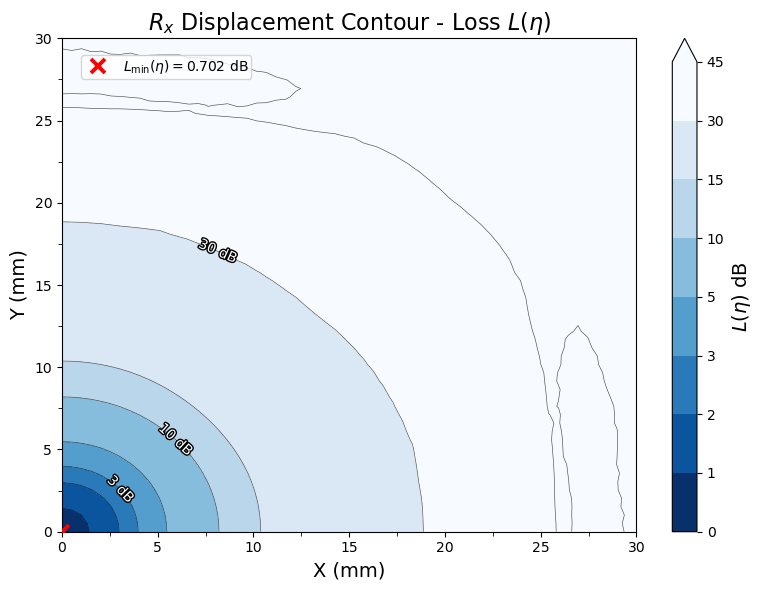

(<Figure size 800x600 with 2 Axes>,
 <Axes: title={'center': '$R_x$ Displacement Contour - Loss $L(\\eta)$'}, xlabel='X (mm)', ylabel='Y (mm)'>)

In [138]:
plot_zemax_2d_loss_contours(
    "FibreCouplingDisplacement2D_flippedY.npz",
    title=r"$R_x$ Displacement Contour - Loss $L(\eta)$",
    vmax_db=45,
    savepath="Zemax_rx_displacement_contour.pdf",
    flip_y=False,
    xlabel="X (mm)",
    ylabel="Y (mm)",
    legend_loc="upper left"
)

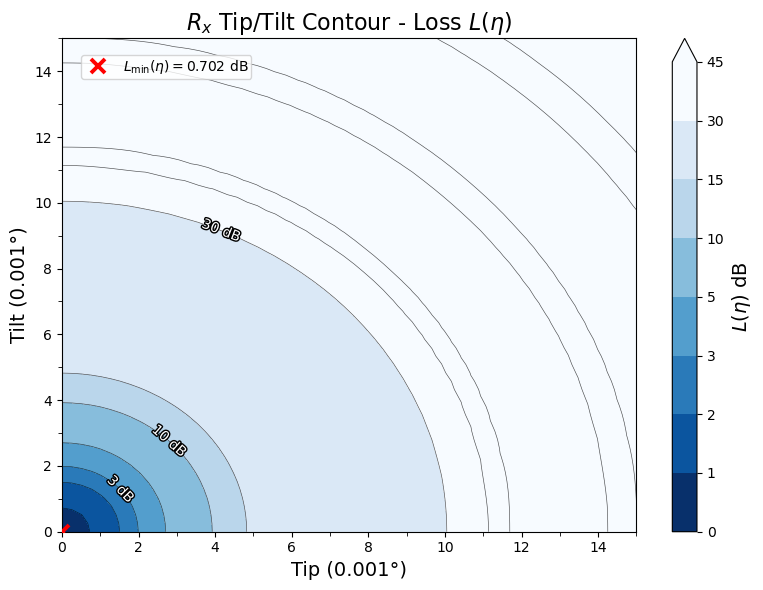

(<Figure size 800x600 with 2 Axes>,
 <Axes: title={'center': '$R_x$ Tip/Tilt Contour - Loss $L(\\eta)$'}, xlabel='Tip (0.001°)', ylabel='Tilt (0.001°)'>)

In [140]:
plot_zemax_2d_loss_contours(
    "FibreCouplingTiltDegrees2D_flippedY.npz",
    title=r"$R_x$ Tip/Tilt Contour - Loss $L(\eta)$",
    vmax_db=45,
    savepath="Zemax_rx_tiptilt_contour.pdf",
    flip_y=False,
    xlabel="Tip (0.001°)",
    ylabel="Tilt (0.001°)",
    legend_loc="upper left"
)

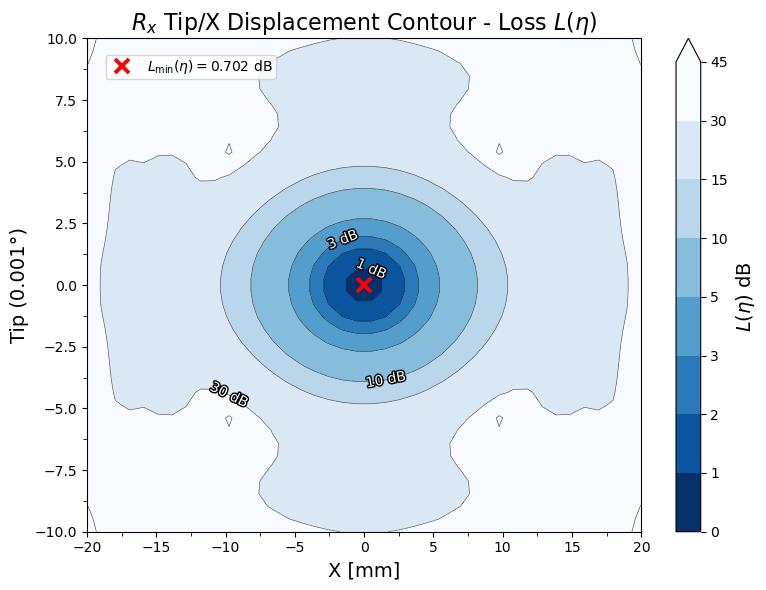

(<Figure size 800x600 with 2 Axes>,
 <Axes: title={'center': '$R_x$ Tip/X Displacement Contour - Loss $L(\\eta)$'}, xlabel='X [mm]', ylabel='Tip (0.001°)'>)

In [142]:
plot_zemax_2d_loss_contours(
    "FibreCouplingXTiltXDisplacement2D_flippedY.npz",
    title=r"$R_x$ Tip/X Displacement Contour - Loss $L(\eta)$",
    vmax_db=45,
    savepath="Zemax_rx_tipxdisplacement_contour.pdf",
    flip_y=False,
    xlabel="X [mm]",
    ylabel="Tip (0.001°)",
    legend_loc="upper left"
)

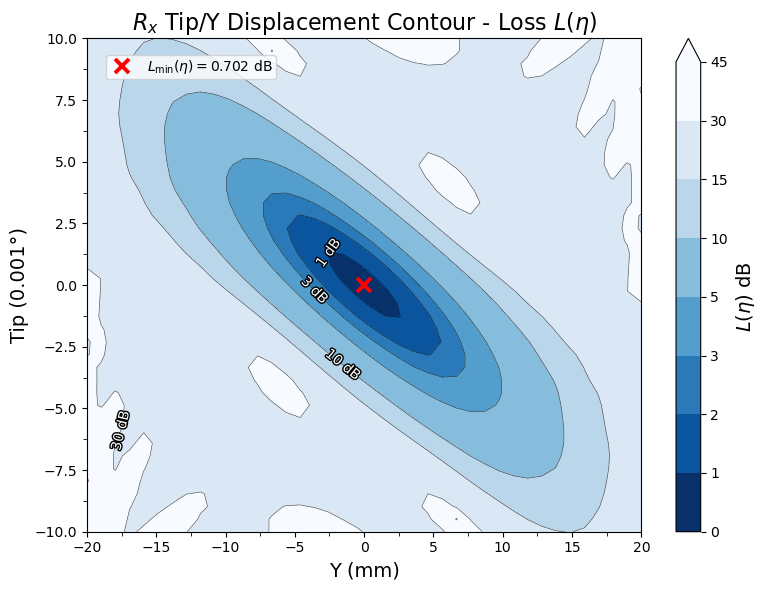

(<Figure size 800x600 with 2 Axes>,
 <Axes: title={'center': '$R_x$ Tip/Y Displacement Contour - Loss $L(\\eta)$'}, xlabel='Y (mm)', ylabel='Tip (0.001°)'>)

In [144]:
plot_zemax_2d_loss_contours(
    "FibreCouplingXTiltYDisplacement2D_flippedY.npz",
    title=r"$R_x$ Tip/Y Displacement Contour - Loss $L(\eta)$",
    vmax_db=45,
    savepath="Zemax_rx_tipydisplacement_contour.pdf",
    flip_y=False,
    xlabel="Y (mm)",
    ylabel="Tip (0.001°)",
    legend_loc="upper left"
)